# Notebook 03: Zero-Intelligence Model

**Paper Reference:** Gould et al. (2013), Section 5.2.4 — *Continuous-time models*

The Smith et al. (2003) zero-intelligence (ZI) model is the foundational stochastic LOB model. Its assumptions:

1. **Limit orders** arrive as a Poisson process at rate $\lambda$ per tick per unit time, uniformly across a price range
2. **Market orders** arrive as a Poisson process at rate $\mu$ per unit time
3. Each active order is **cancelled** independently at rate $\delta$ per unit time

Despite having *zero intelligence* (no strategic behavior), this model produces a realistic-looking LOB with an emergent spread and depth profile.

In [1]:
import sys
sys.path.insert(0, '..')

from lob.book import OrderBook
from lob.order import Side, reset_order_id_counter
from lob.matching import PriceTimeEngine
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.metrics import compute_log_returns
from lob.analysis.plotting import (
    set_style, plot_price_series, plot_depth_profile,
    plot_return_distribution, plot_spread_timeseries, plot_acf
)
from lob.analysis.stylized_facts import compute_acf
import numpy as np
import matplotlib.pyplot as plt

set_style()
reset_order_id_counter()

## 1. Model Parameters

The key parameters and their interpretation:

| Parameter | Symbol | Meaning |
|-----------|--------|---------|
| `mu` | $\mu$ | Market order arrival rate |
| `lam` | $\lambda$ | Limit order arrival rate per tick |
| `delta` | $\delta$ | Cancellation rate per order |
| `price_range` | $L$ | Number of ticks on each side |

Smith et al. showed that the model's behavior depends on the **dimensionless ratios** $\mu / \lambda$ and $\delta / \lambda$.

In [2]:
# Configure the ZI model
model = SmithFarmerModel(
    mu=1.0,          # 1 market order per unit time
    lam=0.5,         # 0.5 limit orders per tick per unit time
    delta=0.1,       # each order cancelled at rate 0.1
    price_range=50,  # limit orders within 50 ticks of mid
    initial_mid=10000,
    lot_size=1,
)

config = SimulationConfig(
    n_events=50_000,
    warmup_events=5_000,
    seed=42,
)

print(f"Model: Smith et al. (2003) ZI")
print(f"Parameters: mu={model.mu}, lambda={model.lam}, delta={model.delta}")
print(f"Running {config.n_events + config.warmup_events} events ({config.warmup_events} warmup)...")

Model: Smith et al. (2003) ZI
Parameters: mu=1.0, lambda=0.5, delta=0.1
Running 55000 events (5000 warmup)...


In [3]:
# Run the simulation
reset_order_id_counter()
sim = Simulation(model=model, config=config)
df = sim.run(progress=True)
print(f"\nRecorded {len(df)} events")
print(f"Event types: {df['event_type'].value_counts().to_dict()}")

Simulating: 100%|██████████| 55000/55000 [00:01<00:00, 49214.79it/s]



Recorded 50000 events
Event types: {'limit': 25031, 'cancel': 24441, 'market': 528}


## 2. Price Evolution

Despite zero intelligence, the model produces a realistic-looking price series with a well-defined bid-ask spread.

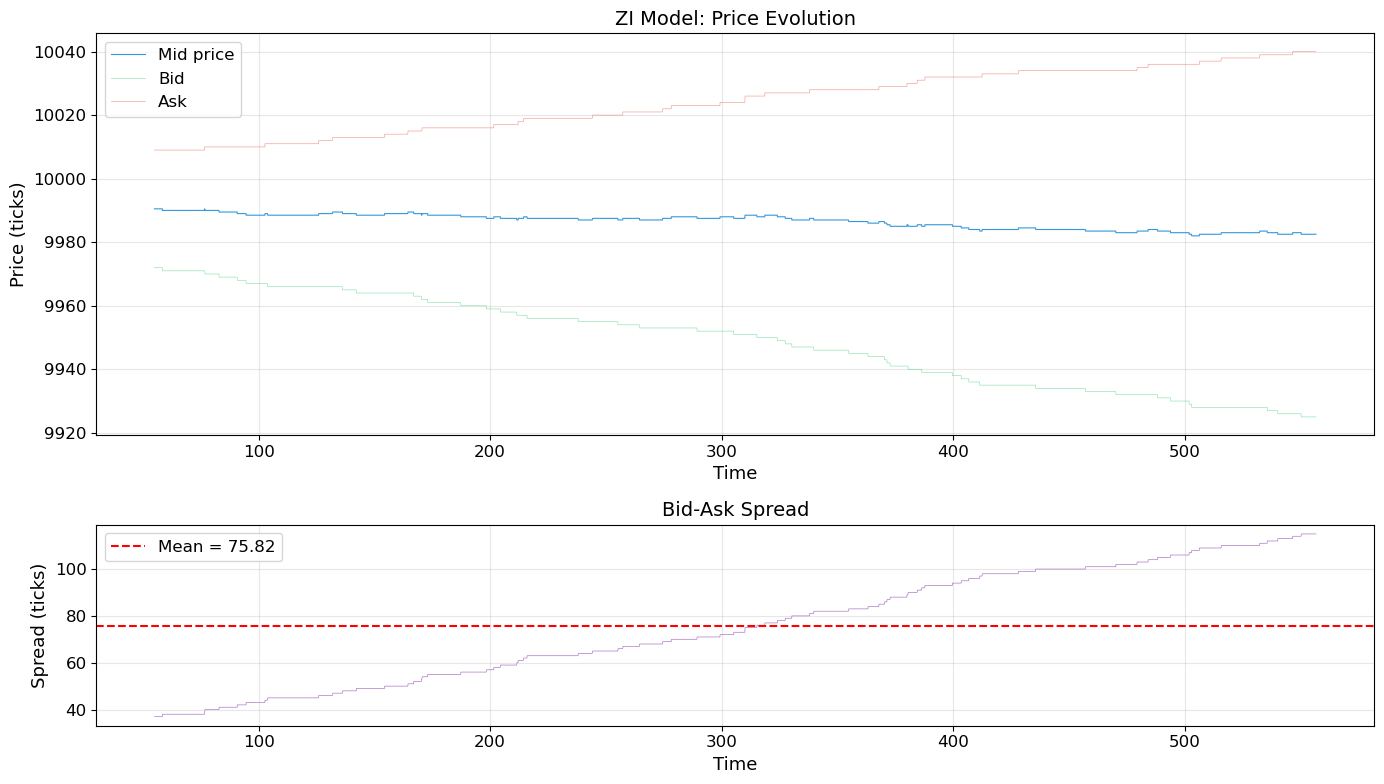

Mean spread: 75.82 ticks
Std of spread: 23.69 ticks


In [4]:
# Filter to events where mid-price is defined
valid = df.dropna(subset=['mid_price']).copy()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [2, 1]})

# Subsample for readability
step = max(1, len(valid) // 5000)
sub = valid.iloc[::step]

plot_price_series(
    sub['time'].values, sub['mid_price'].values,
    bid_prices=sub['best_bid'].values,
    ask_prices=sub['best_ask'].values,
    ax=axes[0]
)
axes[0].set_title('ZI Model: Price Evolution')

plot_spread_timeseries(sub['time'].values, sub['spread'].values, ax=axes[1])

plt.tight_layout()
plt.show()

print(f"Mean spread: {valid['spread'].mean():.2f} ticks")
print(f"Std of spread: {valid['spread'].std():.2f} ticks")

## 3. Emergent Spread

Smith et al. (2003) derived an approximate analytical formula for the mean spread:

$$\langle s \rangle \approx \sqrt{\frac{\mu}{\lambda \delta}}$$

(in the limit of small tick size). Let's compare.

In [5]:
analytical_spread = np.sqrt(model.mu / (model.lam * model.delta))
empirical_spread = valid['spread'].mean()

print(f"Analytical prediction: sqrt(mu / (lambda * delta)) = {analytical_spread:.2f} ticks")
print(f"Empirical mean spread: {empirical_spread:.2f} ticks")
print(f"Ratio: {empirical_spread / analytical_spread:.2f}")
print()
print("Note: The analytical formula is derived under mean-field assumptions")
print("and infinitesimal tick size, so exact agreement is not expected.")

Analytical prediction: sqrt(mu / (lambda * delta)) = 4.47 ticks
Empirical mean spread: 75.82 ticks
Ratio: 16.95

Note: The analytical formula is derived under mean-field assumptions
and infinitesimal tick size, so exact agreement is not expected.


## 4. Depth Profile

The paper reports that empirical depth profiles typically have a **hump shape**, peaking a few ticks away from the best prices. Does the ZI model reproduce this?

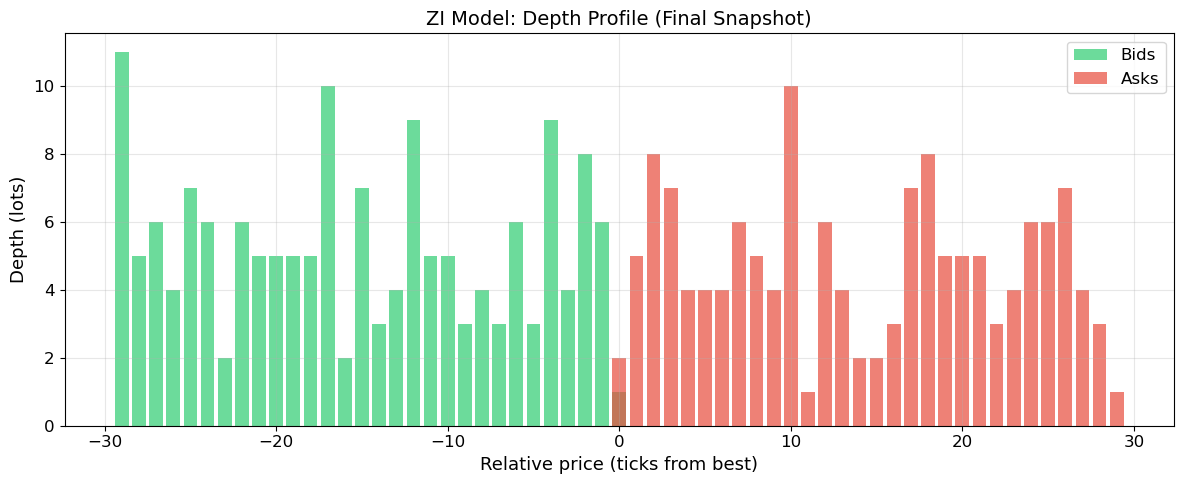

Final book state: 261 bid orders, 241 ask orders


In [6]:
# Take a snapshot of the final book state
fig, ax = plt.subplots(figsize=(12, 5))
plot_depth_profile(sim.book, n_levels=30, ax=ax)
ax.set_title('ZI Model: Depth Profile (Final Snapshot)')
plt.tight_layout()
plt.show()

# Also compute average depth profile across multiple snapshots
print(f"Final book state: {sim.book.num_orders(Side.BID)} bid orders, "
      f"{sim.book.num_orders(Side.ASK)} ask orders")

## 5. Return Distribution

A key empirical stylized fact is that return distributions have **heavy tails** — much heavier than a Gaussian. The ZI model produces returns, but are they heavy-tailed?

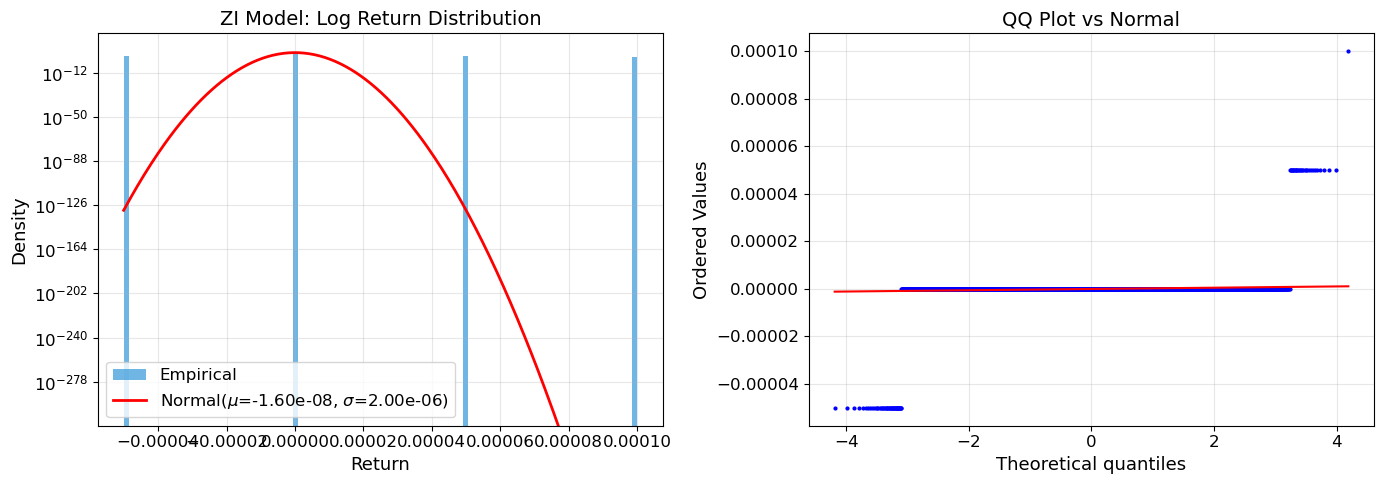

Kurtosis: 715.67 (Gaussian = 0, heavy-tailed > 0)

The ZI model produces returns that are close to Gaussian.
This is a known LIMITATION — real markets have much heavier tails (kurtosis >> 0).


In [7]:
# Compute mid-price returns
mid_prices = valid['mid_price'].values
log_returns = compute_log_returns(mid_prices)
log_returns = log_returns[np.isfinite(log_returns)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_return_distribution(log_returns, n_bins=100, ax=axes[0])
axes[0].set_title('ZI Model: Log Return Distribution')

# QQ plot against normal
from scipy import stats
stats.probplot(log_returns, dist="norm", plot=axes[1])
axes[1].set_title('QQ Plot vs Normal')
axes[1].get_lines()[0].set_markersize(2)

plt.tight_layout()
plt.show()

kurtosis = stats.kurtosis(log_returns)
print(f"Kurtosis: {kurtosis:.2f} (Gaussian = 0, heavy-tailed > 0)")
print(f"\nThe ZI model produces returns that are close to Gaussian.")
print(f"This is a known LIMITATION — real markets have much heavier tails (kurtosis >> 0).")

## 6. Autocorrelation of Returns

The paper notes that mid-price returns in real LOBs show:
- **Negative autocorrelation** at lag 1 (bid-ask bounce)
- **No significant autocorrelation** at higher lags (efficient market)

The ZI model should capture the negative lag-1 autocorrelation mechanically.

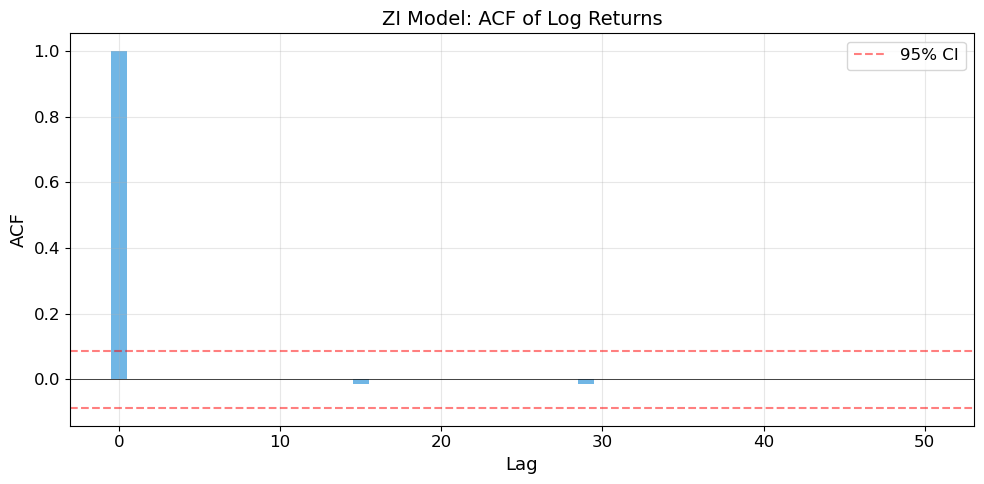

ACF at lag 1: -0.0001
ACF at lag 2: -0.0001

Negative lag-1 autocorrelation is the 'bid-ask bounce' effect:
a buy market order pushes the mid-price up, making a subsequent
sell market order (which pushes it back down) more likely to follow.


In [8]:
acf_returns = compute_acf(log_returns, max_lag=50)

fig, ax = plt.subplots(figsize=(10, 5))
plot_acf(acf_returns, title='ZI Model: ACF of Log Returns', ax=ax)
plt.tight_layout()
plt.show()

print(f"ACF at lag 1: {acf_returns[1]:.4f}")
print(f"ACF at lag 2: {acf_returns[2]:.4f}")
print(f"\nNegative lag-1 autocorrelation is the 'bid-ask bounce' effect:")
print(f"a buy market order pushes the mid-price up, making a subsequent")
print(f"sell market order (which pushes it back down) more likely to follow.")

## 7. Limitations of the ZI Model

From the paper, the ZI model fails to reproduce several key stylized facts:

| Stylized Fact | Real Markets | ZI Model |
|--------------|-------------|----------|
| Heavy-tailed returns | Yes (power-law ~3) | No (nearly Gaussian) |
| Volatility clustering | Yes (strong) | No |
| Long memory in order signs | Yes | No (independent by design) |
| Power-law relative prices | Yes | No (uniform by design) |
| Hump-shaped depth profile | Yes | Partial |

The ZI model serves as a **null model** — a baseline that captures the mechanical effects of the LOB structure without any strategic behavior. Its failures point to which features of real markets require richer explanations.

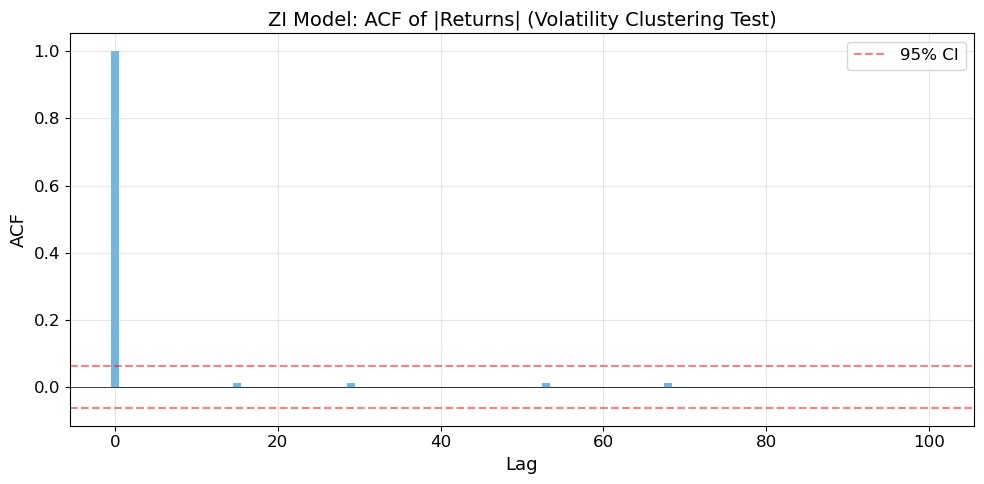

ACF of |returns| at lag 10: -0.0015
ACF of |returns| at lag 50: -0.0015

Real markets show slowly decaying ACF of |returns| (volatility clustering).
The ZI model shows rapid decay — no volatility clustering.


In [9]:
# Volatility clustering check: ACF of absolute returns
abs_returns = np.abs(log_returns)
acf_vol = compute_acf(abs_returns, max_lag=100)

fig, ax = plt.subplots(figsize=(10, 5))
plot_acf(acf_vol, title='ZI Model: ACF of |Returns| (Volatility Clustering Test)', ax=ax)
plt.tight_layout()
plt.show()

print(f"ACF of |returns| at lag 10: {acf_vol[10]:.4f}")
print(f"ACF of |returns| at lag 50: {acf_vol[50]:.4f}")
print(f"\nReal markets show slowly decaying ACF of |returns| (volatility clustering).")
print(f"The ZI model shows rapid decay — no volatility clustering.")

## 8. Parameter Sensitivity

How do the model parameters affect the emergent spread?

In [10]:
# Vary mu/lambda ratio and measure the mean spread
mu_values = [0.5, 1.0, 2.0, 4.0]
lam_values = [0.2, 0.5, 1.0, 2.0]
delta_fixed = 0.1

print(f"{'mu':>6} {'lambda':>8} {'mu/lambda':>10} {'Predicted s':>13} {'Simulated s':>13}")
print("-" * 55)

for mu in [0.5, 1.0, 2.0]:
    for lam in [0.3, 0.5, 1.0]:
        reset_order_id_counter()
        m = SmithFarmerModel(mu=mu, lam=lam, delta=delta_fixed,
                             price_range=50, initial_mid=10000)
        c = SimulationConfig(n_events=10_000, warmup_events=2_000, seed=42)
        s = Simulation(model=m, config=c)
        result = s.run(progress=False)
        valid_r = result.dropna(subset=['spread'])
        emp_spread = valid_r['spread'].mean()
        pred = np.sqrt(mu / (lam * delta_fixed))
        print(f"{mu:>6.1f} {lam:>8.1f} {mu/lam:>10.2f} {pred:>13.2f} {emp_spread:>13.2f}")

    mu   lambda  mu/lambda   Predicted s   Simulated s
-------------------------------------------------------
   0.5      0.3       1.67          4.08         49.70
   0.5      0.5       1.00          3.16         34.80
   0.5      1.0       0.50          2.24         41.00
   1.0      0.3       3.33          5.77         88.28
   1.0      0.5       2.00          4.47         39.25
   1.0      1.0       1.00          3.16         42.04
   2.0      0.3       6.67          8.16        142.81
   2.0      0.5       4.00          6.32         84.82
   2.0      1.0       2.00          4.47         49.98


## Summary

The Smith et al. (2003) ZI model demonstrates that a **surprising amount of LOB structure emerges mechanically** from simple stochastic order flow — without any strategic behavior. However, it misses key empirical facts that require richer models.

**Next:** Notebook 04 catalogs the empirical stylized facts that any serious LOB model should reproduce.